<a href="https://colab.research.google.com/github/marianagomez3108-spec/Facturacion/blob/main/Equipo_5_Series_Temporales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Equipo 5 · Volatilidad: medir la variabilidad de los rendimientos

**Curso:** Series temporales financieras  
**Fuente de datos:** Yahoo Finance mediante `yfinance`  
**Activo principal:** AAPL (Apple Inc.)  
**Período de trabajo:** enero de 2020 a diciembre de 2025

## Misión del equipo
**Pregunta central:** ¿La variabilidad de los rendimientos de AAPL se mantiene igual durante todo el período?

### Objetivos
- Relacionar volatilidad con dispersión de rendimientos.
- Calcular desviación estándar móvil.
- Interpretar cambios de volatilidad con cautela.

### Consulta conceptual obligatoria
Antes de completar el análisis, consulten fuentes confiables y respondan con sus propias palabras:
- ¿Qué mide la desviación estándar?
- ¿Por qué la volatilidad financiera suele calcularse sobre rendimientos?
- ¿Qué diferencia hay entre volatilidad diaria y anualizada?

### Solución consulta conceptual obligatoria

-la desviacion estandar mide que tan dispersos estan los datos respecto
a su promedio. Si es pequeña los valores suelen estar cerca dela media y si es grande los valores se encuentran mas separados.

-
- **Volatilidad diaria:** es la desviación estándar de los rendimientos diarios de un activo. Indica cuánto se mueve el precio, en promedio, de un día a otro.

  **Volatilidad anualizada:** es esa misma medida llevada a escala de un año, para poder comparar activos y periodos en una base común. Se expresa como porcentaje y suele usar los 252 días hábiles de bolsa por año.

  **¿Por qué la volatilidad financiera suele calcularse sobre rendimientos y no sobre precios?**  
- **Los precios no son estacionarios:** tienen tendencia (AAPL pasó de ≈ 72 USD a ≈ 271 USD entre 2020 y 2025), así que su desviación estándar mostraría sobre todo cuánto se movió el nivel del precio y no la variabilidad del día a día. Los rendimientos, en cambio, fluctúan alrededor de un valor cercano a cero y tienen propiedades estadísticas más estables.  
- **Los rendimientos no dependen de la escala:** una caída de 5 USD no significa lo mismo en una acción de 50 USD que en una de 250 USD. El rendimiento porcentual sí se puede comparar entre fechas y entre activos.  
- **Es lo que le importa al inversionista:** la ganancia o pérdida relativa sobre lo invertido.

**Importante:** este notebook es una plantilla de trabajo. Completen los espacios, expliquen el código con sus palabras y no se limiten a ejecutar las celdas. Citen las fuentes consultadas. Los resultados pueden variar según los datos disponibles al descargar.


## 1. Investigación previa
- Definición intuitiva de volatilidad: **[completar]**
- ¿Qué significa una desviación estándar alta de los rendimientos?: **[completar]**
- ¿Qué supuestos adicionales se requieren para anualizar volatilidad?: **[investigar]**

## Solución Investigación previa
- la volatilidad es el grado en que los rendimientos de un activo fluctuan durante un periodo, una volatilidad alta significa que los rendimientos tienden a variar mas y una baja significa que suelen fluctuar menos, esto no significa que el precio este bajando, pueden haber movimientos tanto positivos como negativos

**¿Qué significa una desviación estándar alta de los rendimientos?**

Que los rendimientos diarios se alejan mucho de su promedio: son frecuentes los movimientos fuertes en ambas direcciones. Eso implica más incertidumbre sobre el resultado en un horizonte dado, pero no indica si el activo va a subir o a bajar.

Anualizar la volatilidad multiplicando por √T (por ejemplo, √252 si se parte de datos diarios) requiere varios supuestos además del cálculo de la desviación estándar muestral:

**Retornos independientes (sin autocorrelación serial):** La varianza del retorno acumulado es la suma de las varianzas solo si las covarianzas entre periodos son cero. Con autocorrelación positiva la volatilidad anual se subestima, y con negativa se sobrestima.

**Retornos idénticamente distribuidos con varianza constante (homocedasticidad):** Si hay agrupamiento de volatilidad (GARCH), la volatilidad cambia en el tiempo y el escalamiento por √T deja de ser válido.

**Varianza finita:** Con colas muy pesadas (varianza infinita o muy inestable), el escalamiento pierde significado.

**Retornos logarítmicos (aditivos en el tiempo):** Los retornos de varios periodos se suman, lo que permite escalar la varianza linealmente.
Media (deriva) despreciable o conocida. Si se ignora una media distinta de cero, la desviación estándar por periodo puede sesgar el resultado al agregar.

**Número fijo y consistente de periodos por año:** Por convención se usan 252 días hábiles, 52 semanas o 12 meses y hay que mantener la misma base al comparar activos o mercados.

**Sin efectos de microestructura ni observaciones no sincrónicas:** Los datos de alta frecuencia, con rebote bid-ask o activos ilíquidos con precios desactualizados, introducen autocorrelación artificial.

In [ ]:
!pip -q install yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TICKER = "AAPL"
START = "2020-01-01"
END = "2026-01-01"

datos = yf.download(
    TICKER,
    start=START,
    end=END,
    auto_adjust=True,
    progress=False
)

# Algunas versiones de yfinance pueden devolver columnas MultiIndex.
if isinstance(datos.columns, pd.MultiIndex):
    datos.columns = datos.columns.get_level_values(0)

datos = datos.dropna(how="all")
datos.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.271545,72.331702,71.029923,71.282575,135480400
2020-01-03,71.568924,72.326889,71.345145,71.501549,146322800
2020-01-06,72.139198,72.177699,70.442799,70.693051,118387200
2020-01-07,71.799927,72.403889,71.580958,72.148828,108872000
2020-01-08,72.954918,73.255698,71.503953,71.503953,132079200


## 2. Calcular rendimientos y volatilidad móvil
La desviación estándar móvil de 20 sesiones resume la dispersión de los rendimientos diarios dentro de cada ventana. Aquí se expresa en puntos porcentuales diarios; no es una probabilidad de pérdida.

In [ ]:
datos["Rendimiento_pct"] = datos["Close"].pct_change() * 100
datos["Volatilidad_20"] = datos["Rendimiento_pct"].rolling(20).std()
print("Desviación estándar de rendimientos diarios (%):", round(datos["Rendimiento_pct"].std(), 3))
display(datos[["Rendimiento_pct", "Volatilidad_20"]].tail(10).round(3))

Desviación estándar de rendimientos diarios (%): 2.004


Price,Rendimiento_pct,Volatilidad_20
Date,,
2025-12-17,-1.009,0.961
2025-12-18,0.129,0.958
2025-12-19,0.544,0.937
2025-12-22,-0.987,0.864
2025-12-23,0.513,0.785
2025-12-24,0.532,0.791
2025-12-26,-0.150,0.788
2025-12-29,0.132,0.780
2025-12-30,-0.248,0.681


EXPLICACION CODIGO

pct_change() calcula el cambio relativo entre el cierre de un dia y el anterior. se multiplica por 100 para expresarlo en porcentaje.
rolling(20) calcula la desviacion estandar de los 20 rendimientos diarios mas recientes

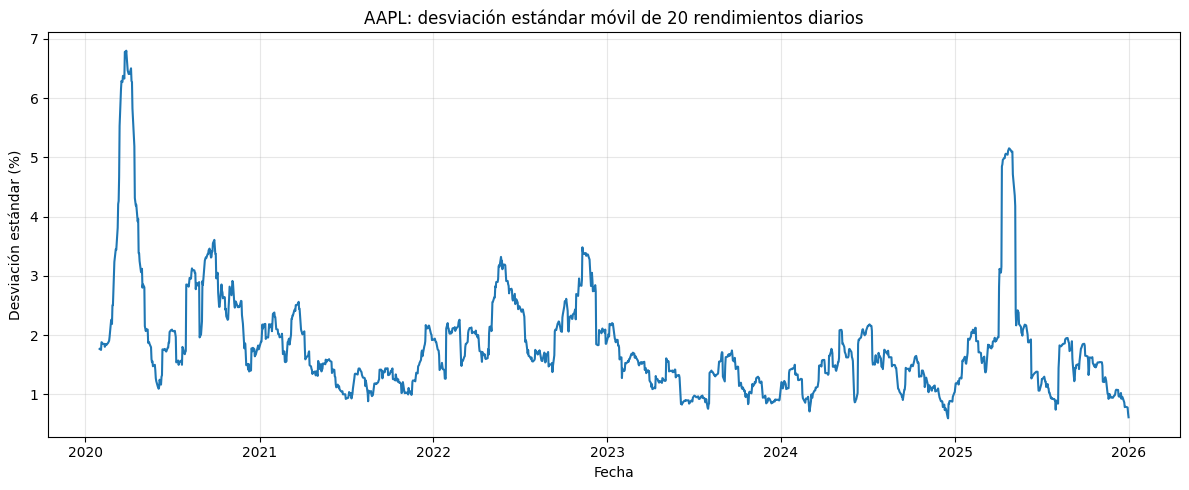

mayor volatilidadmovil:  6.800% el 2020-03-27
menor volatilidadmovil:  0.596% el 2024-12-17
promedio de volatilidad movil: 1.810%


In [ ]:
plt.figure(figsize=(12,5))
plt.plot(datos.index, datos["Volatilidad_20"])
plt.title("AAPL: desviación estándar móvil de 20 rendimientos diarios")
plt.xlabel("Fecha")
plt.ylabel("Desviación estándar (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

vol_valida = datos["Volatilidad_20"].dropna()
fecha_max = vol_valida.idxmax()
fecha_min = vol_valida.idxmin()

print(f"mayor volatilidadmovil: {vol_valida.max(): .3f}% el {fecha_max.date()}")
print(f"menor volatilidadmovil: {vol_valida.min(): .3f}% el {fecha_min.date()}")
print(f"promedio de volatilidad movil: {vol_valida.mean():.3f}%")

## 3. Visualizar cambios en volatilidad


Los picos inidican ventanas de 20 sesiones en las que los rendimientos estuvieron mas dispersos; los valles muestran periodos relativamente mas tranquilos la curva puede subir o bajar con rapidez por que cada nueva sesion entra en la ventana y una sesion antigua sale

,Desviacion_diaria_pct,Rendimiento_promedio_pct,Numero_observaciones,Volatilidad_anualizada_pct
Año,,,,
2020,2.942,0.273,252,46.699
2021,1.581,0.131,252,25.102
2022,2.249,-0.097,251,35.696
2023,1.279,0.168,250,20.300
2024,1.429,0.116,252,22.680
2025,2.048,0.055,250,32.511


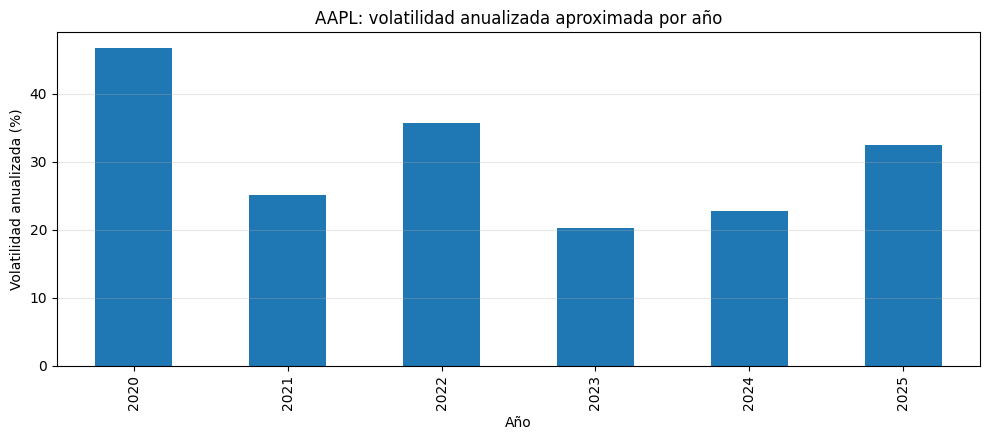

Año con mayor volatilidad anualizada: 2020
Año con menor volatilidad anualizada: 2023


In [ ]:
datos["Año"] = datos.index.year
resumen_anual = datos.groupby("Año")["Rendimiento_pct"].agg(
    Desviacion_diaria_pct="std",
    Rendimiento_promedio_pct="mean",
    Numero_observaciones="count"
)
resumen_anual["Volatilidad_anualizada_pct"] = resumen_anual["Desviacion_diaria_pct"] * np.sqrt(252)

display(resumen_anual.round(3))

plt.figure(figsize=(10, 4.5))
resumen_anual["Volatilidad_anualizada_pct"].plot(kind="bar")
plt.title("AAPL: volatilidad anualizada aproximada por año")
plt.xlabel("Año")
plt.ylabel("Volatilidad anualizada (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

anio_mayor = resumen_anual["Volatilidad_anualizada_pct"].idxmax()
anio_menor = resumen_anual["Volatilidad_anualizada_pct"].idxmin()
print(f"Año con mayor volatilidad anualizada: {anio_mayor}")
print(f"Año con menor volatilidad anualizada: {anio_menor}")

## 4. Interpretación
1. ¿En qué períodos observan mayor y menor volatilidad?

la mayor volatilidad se presento en el año 2020, con un 46,699% lo que indica que los rendimientos de las acciones de APPLE tuvieron variaciones mas amplias. la menor volatilidad se presento en 2023 con un 20,300% lo que significa que los rendimientos fueron relativamente mas estables en comparacion con los demas años analizados
 - **Marzo y abril de 2020:** la volatilidad móvil de 20 sesiones llegó a su máximo, ≈ 6,8 % diario, el 27-mar-2020. En esas semanas están los días más extremos de la muestra: −12,9 % el 16-mar y +12,0 % el 13-mar. El período coincide con el inicio de la pandemia de COVID-19.
  - **Abril y mayo de 2025:** un segundo pico de ≈ 5,2 %, con una caída de −9,3 % el 3-abr y la mayor subida de toda la muestra, +15,3 %, el 9-abr. Coincide con los anuncios de aranceles en EE. UU. y su pausa posterior.
  - **Picos intermedios** (≈ 3,3–3,6 %) en **septiembre y octubre de 2020** y en **mayo y noviembre de 2022**. 2022 fue un año de alzas de tasas de interés y de caída del precio (−28 %).
  - **Menor volatilidad:** **mediados de 2023, el primer trimestre de 2024, diciembre de 2024** (mínimo ≈ 0,60 % el 17-dic-2024) y **la segunda mitad de 2025** (≈ 0,61 % al cierre de diciembre de 2025).

  En conclusión, la variabilidad **no** se mantiene igual durante todo el período: el pico es unas 11 veces mayor que el mínimo. Además, los días de alta volatilidad aparecen agrupados en el tiempo. Las coincidencias con eventos económicos son temporales; para afirmar una causa harían falta más evidencias.

2. ¿Qué significa que la volatilidad aumente aunque el precio suba?

esto signica que el precio de la accion puede estar aumentando, pero sus rendimientos diarios presentan fluctuaciones mas grandes. es decir, la accion puede generar ganancias, pero tambien experimentar caidas y subidas pronunciadas durante el periodo. por eso, un aumento del precio no significa que la inversion sea estable.

La volatilidad mide la dispersión de los rendimientos, no su dirección. El precio puede subir en promedio y aun así hacerlo con saltos grandes y alternados (por ejemplo, +5 %, −3 %, +6 %). Un caso claro es 2020: AAPL subió 78 % y fue el año más volátil de la muestra. Rebotes rápidos como el +15 % del 9-abr-2025 también aumentan la volatilidad. En resumen, la subida de precio y la alta volatilidad pueden ocurrir a la vez: más incertidumbre no significa necesariamente pérdidas.

3. ¿Por qué la desviación estándar no indica por sí sola si una inversión es buena o mala?

porque esta mide el riesgo o la variabilidad de los rendimientos, pero no inidca directamente si una inversion genera ganancias o perdidas. una volatilidad alta puede representar oportunidades de obtener mayores ganancias, pero tambien esta la posibilidad de sufrir perdidas importantes, por eso es necesario analizarlo junto con la rentabilidad y otros indicadores financieros.

- No dice nada del **rendimiento esperado**: la volatilidad debe compararse con la ganancia (por ejemplo, con el índice de Sharpe). En 2023 AAPL tuvo baja volatilidad y +55 %, mientras que en 2022 tuvo volatilidad media y −28 %.
- **Penaliza igual las subidas que las bajadas**, aunque al inversionista solo le perjudican las bajadas.
- **Supone implícitamente una distribución simétrica** y no capta bien las colas gruesas ni los saltos extremos.
- **Depende del horizonte y del perfil del inversionista:** para alguien de largo plazo, la volatilidad diaria puede importar poco. Tampoco considera la diversificación (el aporte del activo al riesgo de un portafolio).

4. ¿Qué limitación introduce elegir una ventana de 20 sesiones?

Esto permite calcular la volatilidad reciente,aproximadamente de un mes bursatil, pero tiene la limitacion de que solo considera los ultimos 20 dias de negociacion por esta razon, puede reaccionar rapidamente ante cambios del mercado y no representar adecuadamente el comportamiewnto a largo plazo. ademas, los resultados pueden variar dependiendo de la ventana elegida

- **Compromiso entre ruido y rezago:** 20 sesiones (≈ 1 mes bursátil) reaccionan rápido pero son ruidosas; una ventana más larga (60 o 252 sesiones) es más suave pero detecta los cambios con retraso.
- **Efecto "fantasma":** un día extremo pesa lo mismo durante 20 sesiones y luego desaparece de golpe, lo que produce saltos artificiales en la curva. Esto se debe a que todos los días tienen el mismo peso; modelos como EWMA o GARCH dan más peso a los datos recientes.
- **Pocas observaciones:** con 20 datos la estimación tiene un error de muestreo considerable.
- **Las primeras 19 observaciones quedan vacías (NaN)**, y el resultado cambia según la ventana elegida, que es una decisión arbitraria del analista.

**Conclusión financiera:**
en conclusion, la volatilidad de las acciones de APPLE no se mantuvo constante entre 2020 y 2025. El año 2020 presento el mayor riesgo por variabilidad, mientras que en 2023 fue el periodo mas estable, esto demuestra la importancia de analizar tnato la volatilidad como la rentabilidad para comprender mejor el comportamiento de una inversion

La volatilidad de los rendimientos de AAPL no fue constante entre 2020 y 2025. Para todo el período, la desviación estándar diaria fue ≈ 2,0 % (≈ 31,8 % anualizada), pero hubo fases muy distintas: episodios de estrés con volatilidad de 5–7 % diario (marzo-abril de 2020 y abril de 2025) y fases de calma por debajo de 1 % (2023, 2024 y el final de 2025). La volatilidad llega en grupos y es persistente, por lo que no conviene usar un solo número para todo el período. Esto también muestra los límites de la anualización con $\sqrt{252}$, que supone varianza constante. Una volatilidad alta indica mayor incertidumbre, no una mala inversión: 2020 fue el año más volátil y también el de mayor rendimiento.

## 5. Fuentes y participación
Fuentes:
- https://brainbound.blog/annualized-volatility-guide

- https://economics.sas.upenn.edu/node/10078

- Hull, J. C. (2022). *Options, Futures, and Other Derivatives* (11.ª ed.). Pearson. Cap. 15 (volatilidad y regla de la raíz del tiempo) y cap. 23 (EWMA y GARCH).
- Tsay, R. S. (2010). *Analysis of Financial Time Series* (3.ª ed.). Wiley. Cap. 1 (rendimientos) y cap. 3 (volatilidad condicional y agrupamiento).
- Investopedia – Volatility: https://www.investopedia.com/terms/v/volatility.asp
- Investopedia – Standard Deviation: https://www.investopedia.com/terms/s/standarddeviation.asp


Aportes de integrantes: **[completar]**

**juan giraldo**

consulta conceptual
investigacion previa
interpretacion
fuentes bibliograficas

**mariana guisao**

consulta conceptual
investigacion previa
graficas
interpretacion

**isabella hincapie**

consulta conceptual
investigacion previa
calculos en python